In [1]:
import torch
print(f"GPU tersedia: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Nama GPU: {torch.cuda.get_device_name(0)}")
    print(f"Jumlah GPU: {torch.cuda.device_count()}")

GPU tersedia: True
Nama GPU: Tesla T4
Jumlah GPU: 2


In [2]:
import os
import re
import warnings
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import KFold
from sklearn.metrics import f1_score

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [3]:
# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MULTILABEL_KFOLD = True
    print("MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MULTILABEL_KFOLD = False
    print("iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)")

iterstrat tidak tersedia, menggunakan KFold standar (Fallback aman)


In [4]:
input_dir = Path("/kaggle/input/competitions/action-2026-data-mining-competition/")
csv_files = {p.name: p for p in input_dir.rglob("*.csv")}
for name, p in csv_files.items():
    print(f"- {name} -> {p}")

- sample_submission.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/sample_submission.csv
- train.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/train.csv
- test.csv -> /kaggle/input/competitions/action-2026-data-mining-competition/test.csv


In [5]:

train_df = pd.read_csv(input_dir / "train.csv")
test_df = pd.read_csv(input_dir / "test.csv")
submission_df = pd.read_csv(input_dir / "sample_submission.csv")
print("berhasil load file")
print(train_df.info())
print(test_df.info())

berhasil load file
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23297 entries, 0 to 23296
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   ID                       23297 non-null  int64 
 1   Teks                     23297 non-null  object
 2   Judul_Caption            21743 non-null  object
 3   Source                   23297 non-null  object
 4   Tanggal_Upload           23297 non-null  object
 5   Infrastruktur            23297 non-null  object
 6   Kesehatan                23297 non-null  object
 7   Administrasi_Perizinan   23297 non-null  object
 8   Lingkungan_Kebersihan    23297 non-null  object
 9   Ketertiban_Umum          23297 non-null  object
 10  Transportasi_LaluLintas  23297 non-null  object
 11  Sosial_Bantuan           23297 non-null  object
 12  Keamanan_Kriminalitas    23297 non-null  object
 13  Pendidikan               23297 non-null  object
dtypes: int64(1), object

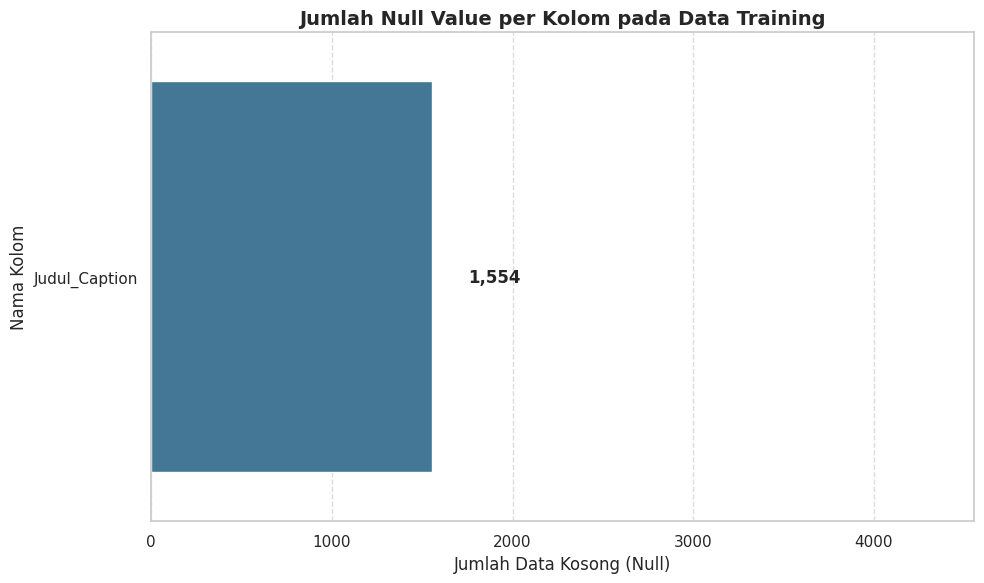

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

null_counts = train_df.isnull().sum()

null_counts = null_counts[null_counts > 0]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=null_counts.values, 
    y=null_counts.index, 
    hue=null_counts.index,      
    palette='mako', 
    legend=False                
)

plt.title('Jumlah Null Value per Kolom pada Data Training', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Data Kosong (Null)', fontsize=12)
plt.ylabel('Nama Kolom', fontsize=12)

for i, v in enumerate(null_counts.values):
    plt.text(v + 200, i, f"{v:,}", va='center', fontsize=12, fontweight='bold')

plt.xlim(0, null_counts.max() + 3000)
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

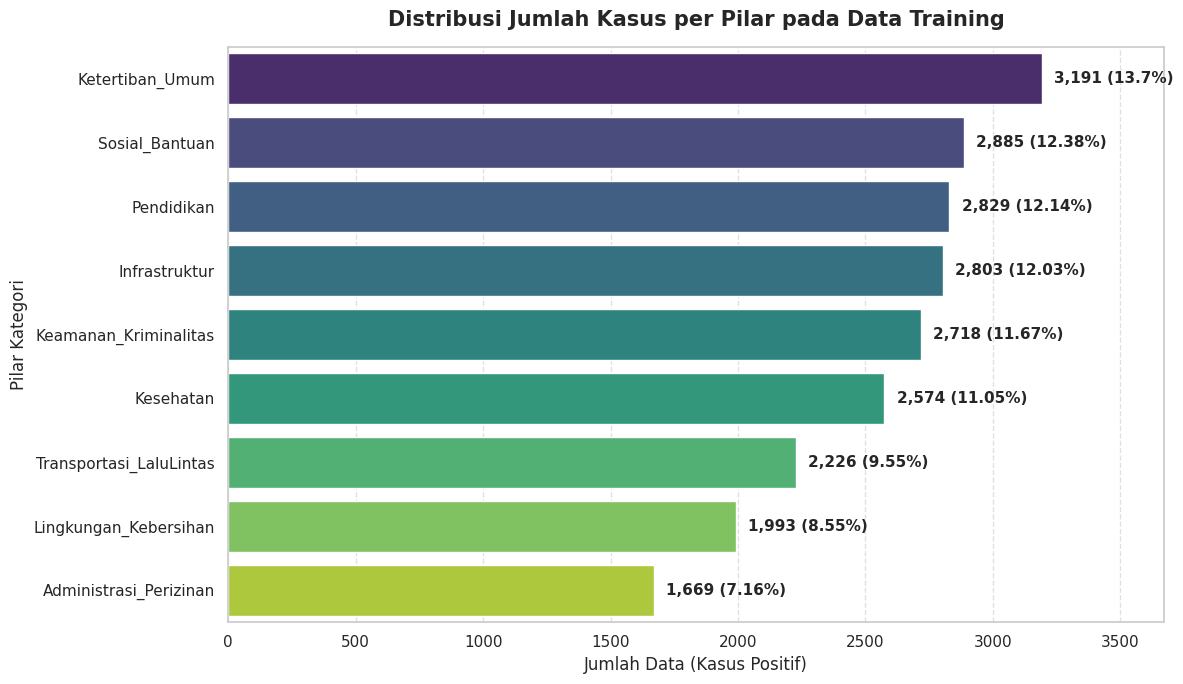


Distribusi Kasus Positif per Pilar:
                  Pilar  Jumlah_Kasus  Persentase
        Ketertiban_Umum          3191       13.70
         Sosial_Bantuan          2885       12.38
             Pendidikan          2829       12.14
          Infrastruktur          2803       12.03
  Keamanan_Kriminalitas          2718       11.67
              Kesehatan          2574       11.05
Transportasi_LaluLintas          2226        9.55
  Lingkungan_Kebersihan          1993        8.55
 Administrasi_Perizinan          1669        7.16

Total sampel training: 23,297

Analisis Class Imbalance:
  Label terbanyak  : Ketertiban_Umum (3,191)
  Label tersedikit : Administrasi_Perizinan (1,669)
  Imbalance Ratio  : 1.9x
  INFO: Distribusi relatif seimbang.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pilar_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]

# ============================================================
# HITUNG DISTRIBUSI KASUS POSITIF PER PILAR
# ============================================================
# Nilai yang dianggap "positif/relevan"
positive_values = ['relevan', '1', 'ya', 'true', 'yes']

pilar_counts = {}
for col in pilar_cols:
    # Normalisasi: strip spasi, lowercase
    normalized = train_df[col].astype(str).str.strip().str.lower()
    # Hitung hanya yang termasuk kategori positif
    count = normalized.isin(positive_values).sum()
    pilar_counts[col] = count

# Buat Series dan urutkan dari yang terbanyak
counts_series = pd.Series(pilar_counts).sort_values(ascending=False)

# ============================================================
# VISUALISASI DISTRIBUSI
# ============================================================
total_samples = len(train_df)
percentage = (counts_series / total_samples * 100).round(2)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=counts_series.values,
    y=counts_series.index,
    hue=counts_series.index,
    palette='viridis',
    legend=False
)

plt.title('Distribusi Jumlah Kasus per Pilar pada Data Training',
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Jumlah Data (Kasus Positif)', fontsize=12)
plt.ylabel('Pilar Kategori', fontsize=12)

# Label angka + persentase di ujung bar
for i, (v, pct) in enumerate(zip(counts_series.values, percentage.values)):
    plt.text(
        v + (counts_series.max() * 0.015),
        i,
        f"{int(v):,} ({pct}%)",
        va='center', fontsize=11, fontweight='bold'
    )

plt.xlim(0, counts_series.max() * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# TABEL RINGKASAN DISTRIBUSI
dist_df = pd.DataFrame({
    'Pilar': counts_series.index,
    'Jumlah_Kasus': counts_series.values,
    'Persentase': percentage.values
})

print("\nDistribusi Kasus Positif per Pilar:")
print(dist_df.to_string(index=False))
print(f"\nTotal sampel training: {total_samples:,}")


max_cases = counts_series.max()
min_cases = counts_series.min()
imbalance_ratio = max_cases / min_cases if min_cases > 0 else float('inf')

print(f"\nAnalisis Class Imbalance:")
print(f"  Label terbanyak  : {counts_series.idxmax()} ({max_cases:,})")
print(f"  Label tersedikit : {counts_series.idxmin()} ({min_cases:,})")
print(f"  Imbalance Ratio  : {imbalance_ratio:.1f}x")

if imbalance_ratio > 5:
    print("  WARNING: Class imbalance signifikan! Perlu perhatian khusus pada label minoritas.")
elif imbalance_ratio > 2:
    print("  INFO: Ada class imbalance moderat. Threshold tuning per label akan membantu.")
else:
    print("  INFO: Distribusi relatif seimbang.")

In [8]:
# BAGIAN 5: HANDLE MISSING VALUES

print("PREPROCESSING: HANDLE MISSING VALUES")

# Isi NaN dengan string kosong (bukan "nan") untuk mencegah artefak
for df in [train_df, test_df]:
    df['Judul_Caption'] = df['Judul_Caption'].fillna('')
    df['Teks'] = df['Teks'].fillna('')

print(" Missing values diisi dengan string kosong")

PREPROCESSING: HANDLE MISSING VALUES
 Missing values diisi dengan string kosong


In [9]:
# BAGIAN 6: UNIVERSAL STRUCTURAL CLEANING

def structural_clean(text):
    """
    Pembersihan struktural tanpa kamus manual:
    1. Normalisasi Unicode (NFKC) - mengatasi fullwidth & cyrillic
    2. Hapus zero-width characters
    3. Lowercasing
    4. Normalisasi whitespace
    """
    if not isinstance(text, str):
        return ""
    
    # NFKC: ubah 'ｓａｍｐａｈ' -> 'sampah', 'КTP' -> 'KTP'
    text = unicodedata.normalize('NFKC', text)
    
    # Hapus karakter tak kasat mata (zero-width)
    text = re.sub(r'[\u200b\u200c\u200d\ufeff\u2060\u00ad\u200e\u200f]', '', text)
    
    # Lowercase
    text = text.lower()
    
    # Normalisasi spasi
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

print("Cleaning teks...")
for df in [train_df, test_df]:
    df['clean_teks'] = df['Teks'].apply(structural_clean)
    df['clean_judul'] = df['Judul_Caption'].apply(structural_clean)
    
    # Sentence-pair: Judul [SEP] Teks
    df['final_text'] = df.apply(
        lambda r: r['clean_teks'] if r['clean_judul'] == ""
                  else f"{r['clean_judul']} [SEP] {r['clean_teks']}",
        axis=1
    )

print(" Structural cleaning selesai")
print(f"  Contoh: '{train_df['final_text'].iloc[0][:100]}...'")

Cleaning teks...
 Structural cleaning selesai
  Contoh: 'menteri hak asasi manusia (ham) natalius pigai melarang aparat kepolisian zrarzonx langsung pelaku b...'


In [10]:
# BAGIAN 7 + 8 + 9 GABUNGAN:
# FEATURE EXTRACTION + NBSVM + OOF ENSEMBLE TRAINING

import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score


# 7.1 - DEFINISI KOLOM TARGET
target_cols = [
    'Infrastruktur', 'Kesehatan', 'Administrasi_Perizinan',
    'Lingkungan_Kebersihan', 'Ketertiban_Umum', 'Transportasi_LaluLintas',
    'Sosial_Bantuan', 'Keamanan_Kriminalitas', 'Pendidikan'
]


# 7.2 - VERIFIKASI train_df, test_df, dan final_text

if 'train_df' not in dir() or 'test_df' not in dir():
    raise NameError(
        "train_df atau test_df belum ada. "
        "Jalankan BAGIAN 2 (Load Data) terlebih dahulu."
    )

if 'final_text' not in train_df.columns or 'final_text' not in test_df.columns:
    raise ValueError(
        "Kolom 'final_text' belum ada. "
        "Jalankan BAGIAN 5 (Missing Values) dan BAGIAN 6 (Cleaning) terlebih dahulu."
    )

# ============================================================
# 7.3 - TF-IDF VECTORIZATION
# ============================================================
print("="*60)
print("FEATURE EXTRACTION: TF-IDF (WORD + CHAR N-GRAM)")
print("="*60)

# Word n-gram: menangkap frasa seperti "rumah sakit"
tfidf_word = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

# Char n-gram: menangkap typo/leetspeak (54mp4h ~ sampah)
tfidf_char = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

print("Fitting TF-IDF pada data train...")
X_word_train = tfidf_word.fit_transform(train_df['final_text'])
X_char_train = tfidf_char.fit_transform(train_df['final_text'])
X_train = hstack([X_word_train, X_char_train]).tocsr()

print("Transforming data test...")
X_word_test = tfidf_word.transform(test_df['final_text'])
X_char_test = tfidf_char.transform(test_df['final_text'])
X_test = hstack([X_word_test, X_char_test]).tocsr()

# PERBAIKAN: ENCODE TARGET DARI STRING KE INTEGER (0 dan 1)

# 1. Buat fungsi mapping yang aman
def encode_target(val):
    if pd.isna(val):
        return 0
    val_str = str(val).strip().lower()
    # Jika mengandung kata kunci positif, anggap 1, selain itu 0
    if val_str in ['relevan', '1', 'ya', 'true', 'yes']:
        return 1
    return 0

# 2. Terapkan fungsi ke semua kolom target di DataFrame
print("Mengonversi label 'Relevan'/'Tidak Relevan' menjadi 1/0...")
for col in target_cols:
    train_df[col] = train_df[col].apply(encode_target)

# 3. Sekarang AMAN untuk diubah menjadi numpy array bertipe integer
y_train = train_df[target_cols].astype(int).values

print(f"✓ Target shape: {y_train.shape}, dtype: {y_train.dtype}")
print(f"✓ Contoh 3 baris pertama y_train:\n{y_train[:3]}")

print(f"✓ Fitur train : {X_train.shape}")
print(f"✓ Fitur test  : {X_test.shape}")
print(f"✓ Target shape: {y_train.shape}, dtype: {y_train.dtype}")

# 8 - DEFINISI CLASS NBSVM

print("\n" + "="*60)
print("DEFINISI CLASS NBSVM")
print("="*60)

def get_nb_ratios(X, y_binary):
    """Hitung log-count ratio Naive Bayes untuk satu label biner"""
    p = X[y_binary == 1].sum(axis=0) + 1
    q = X[y_binary == 0].sum(axis=0) + 1
    r = np.log(p / p.sum()) - np.log(q / q.sum())
    return np.asarray(r).flatten()

class NBSVM:
    """NBSVM untuk multi-label: satu model per label"""
    def __init__(self, C=1.0):
        self.C = C
        self.models = []
        self.ratios = []
    
    def fit(self, X, Y):
        self.models = []
        self.ratios = []
        for i in range(Y.shape[1]):
            r = get_nb_ratios(X, Y[:, i])
            self.ratios.append(r)
            X_nb = X.multiply(csr_matrix(r))
            model = LogisticRegression(
                C=self.C, max_iter=1000,
                class_weight='balanced', solver='lbfgs'
            )
            model.fit(X_nb, Y[:, i])
            self.models.append(model)
        return self
    
    def predict_proba(self, X):
        probs = np.zeros((X.shape[0], len(self.models)))
        for i, (model, r) in enumerate(zip(self.models, self.ratios)):
            X_nb = X.multiply(csr_matrix(r))
            probs[:, i] = model.predict_proba(X_nb)[:, 1]
        return probs

print("✓ Class NBSVM siap digunakan")

# 9 - OOF ENSEMBLE TRAINING

print("\n" + "="*60)
print("OOF ENSEMBLE TRAINING: 5-FOLD (LR + NBSVM + SVM)")
print("="*60)

# Cek ketersediaan Multilabel Stratified KFold
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
    HAS_MLSKF = True
    print("✓ MultilabelStratifiedKFold tersedia")
except ImportError:
    HAS_MLSKF = False
    print("⚠ iterstrat tidak tersedia, fallback ke KFold standar")

N_FOLDS = 5
N_LABELS = len(target_cols)

if HAS_MLSKF:
    kf = MultilabelStratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train, y_train))
else:
    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=42)
    split_iter = list(kf.split(X_train))

# Storage untuk OOF predictions
oof_lr = np.zeros((X_train.shape[0], N_LABELS))
oof_nb = np.zeros((X_train.shape[0], N_LABELS))
oof_svm = np.zeros((X_train.shape[0], N_LABELS))

# Storage untuk test predictions (rata-rata dari 5 fold)
test_lr = np.zeros((X_test.shape[0], N_LABELS))
test_nb = np.zeros((X_test.shape[0], N_LABELS))
test_svm = np.zeros((X_test.shape[0], N_LABELS))

# ============================================================
# LOOP TRAINING PER FOLD
# ============================================================

    # ============================================================
# LOOP TRAINING PER FOLD (FIXED: Loop per Label untuk Multi-Label)
# ============================================================
for fold, (tr_idx, val_idx) in enumerate(split_iter):
    print(f"\n--- Fold {fold + 1}/{N_FOLDS} ---")
    X_tr, X_val = X_train[tr_idx], X_train[val_idx]
    y_tr, y_val = y_train[tr_idx], y_train[val_idx]
    
    # ========================================
    # Model 1: Logistic Regression (per label)
    # ========================================
    print("  Training LogisticRegression (9 labels)...")
    for i in range(N_LABELS):
        lr = LogisticRegression(
            C=1.0, max_iter=1000,
            class_weight='balanced', solver='lbfgs', n_jobs=-1
        )
        lr.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_lr[val_idx, i] = lr.predict_proba(X_val)[:, 1]
        test_lr[:, i] += lr.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # ========================================
    # Model 2: NBSVM (sudah handle multi-label internal)
    # ========================================
    print("  Training NBSVM...")
    nb = NBSVM(C=1.0).fit(X_tr, y_tr)
    oof_nb[val_idx] = nb.predict_proba(X_val)
    test_nb += nb.predict_proba(X_test) / N_FOLDS
    
    # ========================================
    # Model 3: Linear SVM (per label, calibrated)
    # ========================================
    print("  Training LinearSVC calibrated (9 labels)...")
    for i in range(N_LABELS):
        svm_base = LinearSVC(C=1.0, class_weight='balanced', max_iter=2000)
        svm = CalibratedClassifierCV(svm_base, cv=3, method='sigmoid', n_jobs=-1)
        svm.fit(X_tr, y_tr[:, i])  # FAKTA: hanya 1 kolom label (1D)
        oof_svm[val_idx, i] = svm.predict_proba(X_val)[:, 1]
        test_svm[:, i] += svm.predict_proba(X_test)[:, 1] / N_FOLDS
    
    # Progress check
    fold_preds = (oof_lr[val_idx] >= 0.5).astype(int)
    fold_f1 = f1_score(y_val, fold_preds, average='micro', zero_division=0)
    print(f"  Fold {fold + 1} LR Micro-F1 (th=0.5): {fold_f1:.4f}")

print("\n✓ OOF Ensemble Training selesai!")

print(f"  OOF LR shape    : {oof_lr.shape}")
print(f"  OOF NBSVM shape : {oof_nb.shape}")
print(f"  OOF SVM shape   : {oof_svm.shape}")
print(f"  Test LR shape   : {test_lr.shape}")
print(f"  Test NBSVM shape: {test_nb.shape}")
print(f"  Test SVM shape  : {test_svm.shape}")

FEATURE EXTRACTION: TF-IDF (WORD + CHAR N-GRAM)
Fitting TF-IDF pada data train...
Transforming data test...
Mengonversi label 'Relevan'/'Tidak Relevan' menjadi 1/0...
✓ Target shape: (23297, 9), dtype: int64
✓ Contoh 3 baris pertama y_train:
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0 0]]
✓ Fitur train : (23297, 131667)
✓ Fitur test  : (34687, 131667)
✓ Target shape: (23297, 9), dtype: int64

DEFINISI CLASS NBSVM
✓ Class NBSVM siap digunakan

OOF ENSEMBLE TRAINING: 5-FOLD (LR + NBSVM + SVM)
⚠ iterstrat tidak tersedia, fallback ke KFold standar

--- Fold 1/5 ---
  Training LogisticRegression (9 labels)...
  Training NBSVM...
  Training LinearSVC calibrated (9 labels)...
  Fold 1 LR Micro-F1 (th=0.5): 0.8585

--- Fold 2/5 ---
  Training LogisticRegression (9 labels)...
  Training NBSVM...
  Training LinearSVC calibrated (9 labels)...
  Fold 2 LR Micro-F1 (th=0.5): 0.8557

--- Fold 3/5 ---
  Training LogisticRegression (9 labels)...
  Training NBSVM...
  Training LinearSVC

In [11]:
# BAGIAN 10: WEIGHT OPTIMIZATION

best_weights = [1/3, 1/3, 1/3]
best_score = -1

for w1 in np.arange(0.1, 0.8, 0.1):
    for w2 in np.arange(0.1, 0.8 - w1, 0.1):
        w3 = 1.0 - w1 - w2
        if w3 < 0.05:
            continue
        
        preds = ((w1*oof_lr + w2*oof_nb + w3*oof_svm) >= 0.5).astype(int)
        score = f1_score(y_train, preds, average='micro', zero_division=0)
        if score > best_score:
            best_score = score
            best_weights = [w1, w2, w3]

print(f"✓ Best weights:")
print(f"  - LR     : {best_weights[0]:.2f}")
print(f"  - NBSVM  : {best_weights[1]:.2f}")
print(f"  - SVM    : {best_weights[2]:.2f}")
print(f"✓ OOF Micro-F1 (th=0.5): {best_score:.4f}")

✓ Best weights:
  - LR     : 0.10
  - NBSVM  : 0.40
  - SVM    : 0.50
✓ OOF Micro-F1 (th=0.5): 0.8734


In [12]:
# BAGIAN 11: THRESHOLD TUNING PER LABEL

# Gabungkan prediksi dengan weight terbaik
oof_ensemble = best_weights[0]*oof_lr + best_weights[1]*oof_nb + best_weights[2]*oof_svm
test_ensemble = best_weights[0]*test_lr + best_weights[1]*test_nb + best_weights[2]*test_svm

best_thresholds = []
print(f"{'Label':<30s} | {'Threshold':>10s} | {'F1 Score':>10s}")
print("-" * 55)

for i, col in enumerate(target_cols):
    best_th, best_f1 = 0.5, 0
    for th in np.arange(0.10, 0.90, 0.02):
        preds = (oof_ensemble[:, i] >= th).astype(int)
        f1 = f1_score(y_train[:, i], preds, zero_division=0)
        if f1 > best_f1:
            best_f1 = f1
            best_th = th
    best_thresholds.append(best_th)
    print(f"{col:<30s} | {best_th:>10.2f} | {best_f1:>10.4f}")

# Final metrics
oof_final = (oof_ensemble >= np.array(best_thresholds)).astype(int)
micro_f1 = f1_score(y_train, oof_final, average='micro')
macro_f1 = f1_score(y_train, oof_final, average='macro')

print("-" * 55)
print(f"{'FINAL OOF Micro-F1':<30s} | {'':>10s} | {micro_f1:>10.4f}")
print(f"{'FINAL OOF Macro-F1':<30s} | {'':>10s} | {macro_f1:>10.4f}")

Label                          |  Threshold |   F1 Score
-------------------------------------------------------
Infrastruktur                  |       0.54 |     0.7874
Kesehatan                      |       0.30 |     0.9511
Administrasi_Perizinan         |       0.58 |     0.8402
Lingkungan_Kebersihan          |       0.26 |     0.8548
Ketertiban_Umum                |       0.36 |     0.9215
Transportasi_LaluLintas        |       0.48 |     0.8633
Sosial_Bantuan                 |       0.40 |     0.9411
Keamanan_Kriminalitas          |       0.30 |     0.8472
Pendidikan                     |       0.24 |     0.8708
-------------------------------------------------------
FINAL OOF Micro-F1             |            |     0.8775
FINAL OOF Macro-F1             |            |     0.8753


In [13]:
# BAGIAN 12: GENERATE SUBMISSION

# Prediksi test menggunakan threshold optimal
test_preds = np.zeros(test_ensemble.shape)
for i in range(N_LABELS):
    test_preds[:, i] = (test_ensemble[:, i] >= best_thresholds[i]).astype(int)

# Buat DataFrame submission
submission = pd.DataFrame({'ID': test_df['ID']})

# Deteksi format submission (string vs binary)
sample_val = submission_df[target_cols].iloc[0, 0]
if isinstance(sample_val, str) and sample_val.lower() in ['relevan', 'tidak relevan']:
    print("✓ Format: String (Relevan/Tidak Relevan)")
    for i, col in enumerate(target_cols):
        submission[col] = test_preds[:, i].map({1: 'Relevan', 0: 'Tidak Relevan'})
else:
    print("✓ Format: Binary (0/1)")
    for i, col in enumerate(target_cols):
        submission[col] = test_preds[:, i].astype(int)

# Simpan file
# Baris baru yang benar
submission.to_csv('/kaggle/working/submission.csv', index=False)
print("✓ File submission.csv berhasil disimpan!")

print(f"✓ File tersimpan: {submission_path}")
print(f"✓ Shape: {submission.shape}")


print("\nPreview submission:")
print(submission.head())

✓ Format: Binary (0/1)
✓ File tersimpan: /kaggle/working/submission_final_ensemble.csv
✓ Shape: (34687, 10)

Preview submission:
   ID  Infrastruktur  Kesehatan  Administrasi_Perizinan  \
0   1              1          0                       0   
1   2              0          0                       0   
2   3              0          0                       0   
3   4              0          0                       0   
4   5              0          0                       0   

   Lingkungan_Kebersihan  Ketertiban_Umum  Transportasi_LaluLintas  \
0                      0                0                        0   
1                      0                0                        1   
2                      0                1                        0   
3                      0                0                        0   
4                      0                1                        0   

   Sosial_Bantuan  Keamanan_Kriminalitas  Pendidikan  
0               0                      0